<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>Midterm, Part A: search 2 for the denoising autoencoder, grids repeated until nothing changes, on a Colab L4 GPU</p>
<ul>
<li><a href="https://colab.research.google.com/github/NadavFireman/Representation-Learning-Midterm-DAE-SimCLR/blob/main/colab_search2.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"></a></li>
<li>A second search, after colab_experiments.ipynb. It starts from the winner of that search (stage 5) and also tries settings it never tried: a learning-rate scheduler, RAdam, beta2, more weight_decay values, more epochs, and combinations of noise types.</li>
<li>The settings are split into 5 grids of 2 to 4 settings each. A grid tries every combination of its values, with all the other settings at the current best.</li>
<li>After each grid the best settings are updated, and the next grid starts from them. Once all 5 grids ran, the grids run again on the updated settings (pass 2, pass 3) until 5 grids in a row change nothing.</li>
<li>Same rules as search 1: selection by val k-NN top-1 (k = 20, cosine) with a 20,000-image bank, the test set is never used, nothing in the repository's .py files is changed.</li>
<li>The notebook asks Colab for an L4 GPU runtime, and setup 2 stops if the GPU is not an L4. If it opens on another runtime: Runtime, Change runtime type, L4 GPU.</li>
</ul>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>מטלת אמצע, חלק A: חיפוש 2 ל-denoising autoencoder, grids שחוזרים עד שאין שינוי, על GPU מסוג L4 ב-Colab</p>
<ul>
<li>חיפוש שני, אחרי colab_experiments.ipynb. הוא מתחיל מהמנצח של החיפוש ההוא (שלב 5) ובודק גם הגדרות שלא נבדקו שם: ‏scheduler ל-learning rate, ‏RAdam, ‏beta2, עוד ערכים של weight_decay, עוד epochs, ושילובים של סוגי רעש.</li>
<li>ההגדרות מחולקות ל-5 grids, בכל אחד 2 עד 4 הגדרות. ‏grid מנסה כל צירוף של הערכים שלו, וכל שאר ההגדרות נשארות על הטובות הנוכחיות.</li>
<li>אחרי כל grid ההגדרות הטובות מתעדכנות, וה-grid הבא מתחיל מהן. אחרי שכל 5 ה-grids רצו, הם רצים שוב על ההגדרות המעודכנות (‏pass 2, ‏pass 3), עד ש-5 grids ברצף לא משנים כלום.</li>
<li>אותם כללים כמו בחיפוש 1: בחירה לפי val k-NN top-1 (‏k = 20, ‏cosine) עם bank של 20,000 תמונות, ה-test set אף פעם לא בשימוש, ושום דבר בקבצי ה-.py של ה-repository לא משתנה.</li>
<li>המחברת מבקשת מ-Colab סביבת ריצה עם GPU מסוג L4, והכנה 2 נעצרת אם ה-GPU הוא לא L4. אם היא נפתחת על סביבה אחרת: ‏Runtime, ‏Change runtime type, ‏L4 GPU.</li>
</ul>
</div>

<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>The 5 grids</p>
<ul>
<li>G1_noise: noise type {mask, salt_pepper} × noise level {0.5, 0.75, 0.9} × latent_dim {128, 256}: 12 runs. salt_pepper was still improving at 0.75, the edge of search 1.</li>
<li>G2_optimizer: optimizer {adam, adamw, radam} × learning rate {5e-4, 1e-3, 2e-3} × activation {relu, gelu}: 18 runs. The learning rate is tuned with the optimizer, because each optimizer has its own best one. relu + adam is what train.py has built in.</li>
<li>G3_schedule: scheduler {none, cosine, onecycle} × epochs {8, 16} × batch size {256, 512}: 12 runs. Search 1 had a constant learning rate, and its k-NN peaked at epoch 10 and then dropped; a scheduler that lowers the learning rate may change that.</li>
<li>G4_regularization: weight_decay {0, 0.01, 0.05, 0.1} × beta2 {0.99, 0.999}: 8 runs. With Adam weight_decay is not used (it is set to 0), so this grid is then only beta2.</li>
<li>G5_noise_mix: noise type {current, mask+salt_pepper, mix} × extra gaussian noise {0, 0.25, 0.5}: 9 runs. mask+salt_pepper corrupts the same fraction of pixels, a third each to black, white and 0; mix gives every image either mask or salt_pepper at random; the extra gaussian noise is added on top of either.</li>
<li>Every grid also tries the current best value of its settings, so a grid can only keep or improve the best.</li>
<li>A run that was already done with exactly the same settings, in any grid or pass, is not run again: its result is read from Drive.</li>
</ul>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>‏5 ה-grids</p>
<ul>
<li>‏G1_noise: סוג רעש {mask, salt_pepper} × עוצמת רעש {0.5, 0.75, 0.9} × latent_dim {128, 256}: ‏12 ריצות. ‏salt_pepper עדיין השתפר ב-0.75, הקצה של חיפוש 1.</li>
<li>‏G2_optimizer: ‏optimizer {adam, adamw, radam} × learning rate {5e-4, 1e-3, 2e-3} × activation {relu, gelu}: ‏18 ריצות. ה-learning rate נבדק יחד עם ה-optimizer, כי לכל optimizer יש learning rate טוב משלו. ‏relu + adam זה מה שכתוב קבוע ב-train.py.</li>
<li>‏G3_schedule: ‏scheduler {none, cosine, onecycle} × epochs {8, 16} × batch size {256, 512}: ‏12 ריצות. בחיפוש 1 ה-learning rate היה קבוע, וה-k-NN הגיע לשיא ב-epoch 10 ואז ירד; ‏scheduler שמוריד את ה-learning rate יכול לשנות את זה.</li>
<li>‏G4_regularization: ‏weight_decay {0, 0.01, 0.05, 0.1} × beta2 {0.99, 0.999}: ‏8 ריצות. עם Adam אין weight_decay (הוא נקבע ל-0), אז ה-grid הזה בודק רק beta2.</li>
<li>‏G5_noise_mix: סוג רעש {הנוכחי, mask+salt_pepper, mix} × רעש gaussian נוסף {0, 0.25, 0.5}: ‏9 ריצות. ‏mask+salt_pepper משחית את אותו חלק של הפיקסלים, שליש לשחור, שליש ללבן ושליש ל-0; ‏mix נותן לכל תמונה באקראי mask או salt_pepper; ה-gaussian הנוסף מתווסף מעל כל אחד מהם.</li>
<li>כל grid מנסה גם את הערך הטוב הנוכחי של ההגדרות שלו, כך ש-grid יכול רק להשאיר את הטוב או לשפר אותו.</li>
<li>ריצה שכבר רצה עם בדיוק אותן הגדרות, בכל grid או pass, לא רצה שוב: התוצאה שלה נקראת מה-Drive.</li>
</ul>
</div>

<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>Setup 1: clone the repository</p>
<ul>
<li>Downloads the code from GitHub into /content and moves into it. Run it once per runtime.</li>
<li>If the repository is already on this runtime, git clone fails; run the next cell instead.</li>
</ul>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>הכנה 1: שכפול ה-repository</p>
<ul>
<li>מוריד את הקוד מ-GitHub לתיקייה ‎/content ונכנס אליו. מריצים פעם אחת בכל סביבת ריצה.</li>
<li>אם ה-repository כבר נמצא בסביבת הריצה, git clone נכשל; במקרה כזה מריצים את התא הבא.</li>
</ul>
</div>

In [1]:
import os

REPO_DIR = "/content/Representation-Learning-Midterm-DAE-SimCLR"
!git clone https://github.com/NadavFireman/Representation-Learning-Midterm-DAE-SimCLR.git
os.chdir(REPO_DIR)
!pwd

Cloning into 'Representation-Learning-Midterm-DAE-SimCLR'...
remote: Enumerating objects: 36, done.
remote: Counting objects: 100% (36/36), done.
remote: Compressing objects: 100% (24/24), done.
remote: Total 36 (delta 15), reused 33 (delta 12), pack-reused 0 (from 0)
Receiving objects: 100% (36/36), 408.73 KiB | 31.44 MiB/s, done.
Resolving deltas: 100% (15/15), done.
/content/Representation-Learning-Midterm-DAE-SimCLR


<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>Setup 1 (again): pull the latest code</p>
<ul>
<li>Instead of the clone cell, when the repository is already on this runtime: git pull brings the latest commits.</li>
</ul>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>הכנה 1 (שוב): משיכת הקוד העדכני</p>
<ul>
<li>במקום תא השכפול, כשה-repository כבר נמצא בסביבת הריצה: ‏git pull מביא את ה-commits האחרונים.</li>
</ul>
</div>

In [2]:
import os

REPO_DIR = "/content/Representation-Learning-Midterm-DAE-SimCLR"
os.chdir(REPO_DIR)
!git pull
!pwd

Already up to date.
/content/Representation-Learning-Midterm-DAE-SimCLR


<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>Setup 2: install the requirements and check that the GPU is an L4</p>
<ul>
<li>Installs requirements.txt.</li>
<li>Stops with an error if there is no GPU or if it is not an NVIDIA L4: the time estimates and batch size 512 assume an L4.</li>
</ul>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>הכנה 2: התקנת החבילות ובדיקה שה-GPU הוא L4</p>
<ul>
<li>מתקין את requirements.txt.</li>
<li>נעצר עם שגיאה אם אין GPU או אם הוא לא NVIDIA L4: הערכות הזמן ו-batch size 512 מניחים L4.</li>
</ul>
</div>

In [3]:
%pip install -q -r requirements.txt

import torch
assert torch.cuda.is_available(), "No GPU. Runtime → Change runtime type → L4 GPU, then rerun this cell."
gpu = torch.cuda.get_device_name(0)
assert "L4" in gpu, f"The GPU is {gpu}, not an L4. Runtime → Change runtime type → L4 GPU, then rerun this cell."
print(gpu)

NVIDIA L4


<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>Setup 3: Google Drive</p>
<ul>
<li>Mounts Google Drive. LOG_DIR is the folder of search 2, next to the folder of search 1 (search) and apart from it.</li>
<li>Every run, its checkpoints and state.json (the current best settings and the history of the grids) are kept there, so a new runtime continues where the last one stopped.</li>
</ul>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>הכנה 3: ‏Google Drive</p>
<ul>
<li>מחבר את Google Drive. ‏LOG_DIR היא התיקייה של חיפוש 2, ליד התיקייה של חיפוש 1 (‏search) ונפרדת ממנה.</li>
<li>כל הריצות, ה-checkpoints שלהן ו-state.json (ההגדרות הטובות הנוכחיות וההיסטוריה של ה-grids) נשמרים שם, כך שסביבת ריצה חדשה ממשיכה מאיפה שהקודמת עצרה.</li>
</ul>
</div>

In [4]:
from google.colab import drive

drive.mount("/content/drive")
LOG_DIR = "/content/drive/MyDrive/לימודים/תואר שני/שנה ב/סמסטר א/למידת ייצוגים במודלים עמוקים/מטלות/מטלת אמצע/rl_midterm_experiments/search2"
os.makedirs(LOG_DIR, exist_ok=True)
print(LOG_DIR)

Mounted at /content/drive
/content/drive/MyDrive/לימודים/תואר שני/שנה ב/סמסטר א/למידת ייצוגים במודלים עמוקים/מטלות/מטלת אמצע/rl_midterm_experiments/search2


<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>Setup 4: import the repository code</p>
<ul>
<li>Imports the repository modules as they are: config, ImageDataModule, DenoisingAutoEncoder and the callbacks.</li>
<li>SEARCH_BANK_SIZE = 20,000: the class-balanced k-NN bank of the search, as in search 1.</li>
<li>MIN_GAIN = 0.002: a grid's winner replaces the best settings only if it is better by more than this. In search 1 the val k-NN of one run moved by about 0.003 from one epoch to the next (stage 6), so smaller gaps are treated as noise.</li>
<li>MAX_PASSES = 3: at most 3 passes over the 5 grids.</li>
<li>get_dm builds the Tiny-ImageNet datamodule once per batch size and reuses it.</li>
</ul>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>הכנה 4: ייבוא הקוד מה-repository</p>
<ul>
<li>מייבא את המודולים של ה-repository כמו שהם: ‏config, ‏ImageDataModule, ‏DenoisingAutoEncoder וה-callbacks.</li>
<li>‏SEARCH_BANK_SIZE = 20,000: ה-bank המאוזן לפי מחלקות של ה-k-NN בחיפוש, כמו בחיפוש 1.</li>
<li>‏MIN_GAIN = 0.002: המנצח של grid מחליף את ההגדרות הטובות רק אם הוא טוב יותר ביותר מזה. בחיפוש 1 ה-val k-NN של אותה ריצה קפץ בבערך 0.003 מ-epoch ל-epoch (שלב 6), ולכן פערים קטנים יותר נחשבים רעש.</li>
<li>‏MAX_PASSES = 3: לכל היותר 3 מעברים על 5 ה-grids.</li>
<li>‏get_dm בונה את ה-datamodule של Tiny-ImageNet פעם אחת לכל batch size ומשתמש בו שוב.</li>
</ul>
</div>

In [5]:
import itertools
import json
import logging
import sys
import time
import warnings

import matplotlib.pyplot as plt
import pandas as pd
import pytorch_lightning as pl
import torch
from pytorch_lightning.callbacks import ModelCheckpoint
from pytorch_lightning.loggers import TensorBoardLogger
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
from torch import nn, optim

sys.path.insert(0, REPO_DIR)
import config
from callbacks import ColabProgressBar, EpochMetricsCallback, KNNCallback
from datamodule import ImageDataModule
from model import DenoisingAutoEncoder

torch.set_float32_matmul_precision("medium")
warnings.filterwarnings("ignore", ".*does not have many workers.*")
logging.getLogger("pytorch_lightning").setLevel(logging.ERROR)

SEARCH_BANK_SIZE = 20000  # class-balanced k-NN memory bank during the search (100 per class)
MIN_GAIN = 0.002  # a smaller improvement does not replace the best settings (epoch-to-epoch noise is about 0.003)
MAX_PASSES = 3
NUM_WORKERS = min(8, os.cpu_count() or 2)  # an L4 runtime has more CPU cores than config.NUM_WORKERS = 2 assumes

_datamodules = {}


def get_dm(batch_size):
    """The Tiny-ImageNet datamodule for this batch size, built once and reused."""
    if batch_size not in _datamodules:
        dm = ImageDataModule(
            data_dir=config.DATA_DIR,
            batch_size=batch_size,
            num_workers=NUM_WORKERS,
            dataset_name="TinyImageNet",
            label_fraction=1.0,  # the DAE uses every training image and no labels
            seed=config.SEED,
        )
        dm.prepare_data()
        dm.setup("fit")
        _datamodules[batch_size] = dm
    return _datamodules[batch_size]


print("workers:", NUM_WORKERS, "| train images:", len(get_dm(512).train_ds), "| val images:", len(get_dm(512).val_ds))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/3.90k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/3.52k [00:00<?, ?B/s]

data/train-00000-of-00001-1359597a978bc4(…): reconstructing file:   0%|          |  0.00B /  146MB            

data/train-00000-of-00001-1359597a978bc4(…): downloading bytes:           |  0.00B            

data/valid-00000-of-00001-70d52db3c749a9(…): reconstructing file:   0%|          |  0.00B / 14.6MB            

data/valid-00000-of-00001-70d52db3c749a9(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/100000 [00:00<?, ? examples/s]

Generating valid split:   0%|          | 0/10000 [00:00<?, ? examples/s]

workers: 8 | train images: 90000 | val images: 10000


<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>Setup 5: SearchDAE, the repository DAE with every setting of the search</p>
<ul>
<li>A subclass of DenoisingAutoEncoder, as in search 1, so model.py is not changed.</li>
<li>activation: every nn.ReLU of the encoder and the decoder is replaced by nn.ReLU, nn.GELU, nn.SiLU or nn.Mish. None of them has weights, so the initial weights are the same for every activation.</li>
<li>optimizer: torch's Adam, AdamW or RAdam, with betas (0.9, beta2). AdamW and RAdam use weight_decay (decoupled, as in AdamW); Adam does not.</li>
<li>scheduler: none (constant learning rate, as in search 1), cosine (CosineAnnealingLR: the learning rate falls along a cosine to 0 at the last epoch) or onecycle (OneCycleLR: it rises for the first 30% of the steps up to the learning rate, then falls to almost 0; cycle_momentum=False keeps beta1 fixed, so only the learning rate changes). Both are torch built-ins, returned from configure_optimizers as Lightning expects.</li>
<li>add_noise: gaussian, mask and salt_pepper call the repository's own add_noise, so they are exactly as in model.py. mask+salt_pepper: one random number per pixel, as in model.py; a noise_level fraction of the pixels is corrupted, a third each to black, white and 0. mix: every image gets mask or salt_pepper at random. gauss_extra > 0 adds gaussian noise with that std on top. Every random number comes from the same generator, so the val noise stays fixed, as in model.py.</li>
<li>batch_size and epochs are not used by the model; they are arguments only so that save_hyperparameters writes them with the rest of the run's settings.</li>
</ul>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>הכנה 5: ‏SearchDAE, ה-DAE של ה-repository עם כל ההגדרות של החיפוש</p>
<ul>
<li>מחלקה יורשת של DenoisingAutoEncoder, כמו בחיפוש 1, כך ש-model.py לא משתנה.</li>
<li>‏activation: כל nn.ReLU ב-encoder וב-decoder מוחלף ב-nn.ReLU, ‏nn.GELU, ‏nn.SiLU או nn.Mish. לאף אחד מהם אין משקלים, ולכן המשקלים ההתחלתיים זהים בכל activation.</li>
<li>‏optimizer: ה-Adam, ה-AdamW או ה-RAdam של torch, עם betas (0.9, beta2). ‏AdamW ו-RAdam משתמשים ב-weight_decay (מנותק, כמו ב-AdamW); ‏Adam לא.</li>
<li>‏scheduler: ‏none (‏learning rate קבוע, כמו בחיפוש 1), ‏cosine (‏CosineAnnealingLR: ה-learning rate יורד לאורך קוסינוס עד 0 ב-epoch האחרון) או onecycle (‏OneCycleLR: עולה ב-30% הראשונים של הצעדים עד ה-learning rate, ואז יורד כמעט ל-0; ‏cycle_momentum=False משאיר את beta1 קבוע, כך שרק ה-learning rate משתנה). שניהם מובנים ב-torch, ומוחזרים מ-configure_optimizers כמו ש-Lightning מצפה.</li>
<li>‏add_noise: ‏gaussian, ‏mask ו-salt_pepper קוראים ל-add_noise של ה-repository עצמו, ולכן הם בדיוק כמו ב-model.py. ‏mask+salt_pepper: מספר אקראי אחד לכל פיקסל, כמו ב-model.py; חלק noise_level של הפיקסלים מושחת, שליש לשחור, שליש ללבן ושליש ל-0. ‏mix: כל תמונה מקבלת באקראי mask או salt_pepper. ‏gauss_extra > 0 מוסיף מעל זה רעש gaussian עם סטיית התקן הזאת. כל המספרים האקראיים באים מאותו generator, כך שרעש ה-val נשאר קבוע, כמו ב-model.py.</li>
<li>‏batch_size ו-epochs לא משמשים את המודל; הם ארגומנטים רק כדי ש-save_hyperparameters יכתוב אותם עם שאר ההגדרות של הריצה.</li>
</ul>
</div>

In [6]:
ACTIVATIONS = {"relu": nn.ReLU, "gelu": nn.GELU, "silu": nn.SiLU, "mish": nn.Mish}
OPTIMIZERS = {"adam": optim.Adam, "adamw": optim.AdamW, "radam": optim.RAdam}


class SearchDAE(DenoisingAutoEncoder):
    def __init__(self, learning_rate, latent_dim, noise_type, noise_level, activation="relu", optimizer="adam",
                 weight_decay=0.0, beta2=0.999, scheduler="none", batch_size=256, epochs=8, gauss_extra=0.0):
        super().__init__(learning_rate, latent_dim, noise_type, noise_level)
        self.save_hyperparameters()  # all the arguments above -> self.hparams and hparams.yaml
        for layers in (self.encoder, self.decoder):
            for i, layer in enumerate(layers):
                if isinstance(layer, nn.ReLU):
                    layers[i] = ACTIVATIONS[activation]()

    def add_noise(self, x, generator=None):
        """The repository's noise types, two combinations of them, and optional extra gaussian noise on top."""
        hp = self.hparams
        level = hp.noise_level
        if hp.noise_type in ("gaussian", "mask", "salt_pepper"):
            x_noisy = super().add_noise(x, generator)  # exactly as in model.py
        else:
            # one random number per pixel, shared by the 3 channels, as in model.py
            r = torch.rand((x.size(0), 1, x.size(2), x.size(3)), generator=generator, device=x.device, dtype=x.dtype)
            if hp.noise_type == "mask+salt_pepper":
                # a level fraction of the pixels is corrupted, a third each: black, white, 0 (mask)
                x_noisy = torch.where(r < level / 3, self.black, x)
                x_noisy = torch.where((r >= level / 3) & (r < 2 * level / 3), self.white, x_noisy)
                x_noisy = torch.where((r >= 2 * level / 3) & (r < level), torch.zeros_like(x), x_noisy)
            elif hp.noise_type == "mix":
                # every image gets one of the two, at random: half mask, half salt_pepper
                use_mask = torch.rand((x.size(0), 1, 1, 1), generator=generator, device=x.device, dtype=x.dtype) < 0.5
                masked = x * (r >= level)
                salted = torch.where(r < level / 2, self.black, x)
                salted = torch.where(r > 1 - level / 2, self.white, salted)
                x_noisy = torch.where(use_mask, masked, salted)
            else:
                raise ValueError(f"unknown noise_type: {hp.noise_type}")
        if hp.gauss_extra > 0:  # extra gaussian noise on top of the corruption above
            x_noisy = x_noisy + hp.gauss_extra * torch.randn(x.shape, generator=generator, device=x.device, dtype=x.dtype)
        return x_noisy

    def configure_optimizers(self):
        hp = self.hparams
        kwargs = {"lr": hp.learning_rate, "betas": (0.9, hp.beta2)}
        if hp.optimizer == "adamw":
            kwargs["weight_decay"] = hp.weight_decay
        elif hp.optimizer == "radam":
            kwargs.update(weight_decay=hp.weight_decay, decoupled_weight_decay=True)
        optimizer = OPTIMIZERS[hp.optimizer](self.parameters(), **kwargs)

        if hp.scheduler == "cosine":
            scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=self.trainer.max_epochs)
            return {"optimizer": optimizer, "lr_scheduler": {"scheduler": scheduler, "interval": "epoch"}}
        if hp.scheduler == "onecycle":
            scheduler = optim.lr_scheduler.OneCycleLR(
                optimizer, max_lr=hp.learning_rate, total_steps=self.trainer.estimated_stepping_batches,
                cycle_momentum=False,  # by default it also moves beta1; here only the learning rate changes
            )
            return {"optimizer": optimizer, "lr_scheduler": {"scheduler": scheduler, "interval": "step"}}
        return optimizer


print(SearchDAE(1e-3, 128, "salt_pepper", 0.75, activation="mish").encoder)

Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (1): Mish()
  (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (3): Mish()
  (4): Flatten(start_dim=1, end_dim=-1)
  (5): Linear(in_features=16384, out_features=128, bias=True)
)


<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>Setup 6: one run, by its settings</p>
<ul>
<li>normalize(settings) sets weight_decay to 0 when the optimizer is Adam (Adam does not use it), so two settings that train the same model get the same name.</li>
<li>run_name(settings) is the run's folder name: every setting in it, for example salt_pepper0.75_l128_gelu_adamw_lr0.001_wd0.01_b20.999_none_e8_bs512_g0 (g = the extra gaussian noise).</li>
<li>train_run(settings) trains one model and logs it to LOG_DIR/runs/name, as in notebook 04 and search 1: TensorBoardLogger, KNNCallback with the 20,000-image bank, EpochMetricsCallback, ModelCheckpoint on val_knn_top1 with save_last=True, precision 16-mixed.</li>
<li>A finished run writes done.json. Any later grid or pass that needs the same settings reads it instead of training again. A run that was cut off continues from its last.ckpt.</li>
<li>The seed is config.TRAIN_SEED for every run, so runs differ only in their settings. The last section repeats the best settings with other seeds.</li>
</ul>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>הכנה 6: ריצה אחת, לפי ההגדרות שלה</p>
<ul>
<li>‏normalize(settings) קובע weight_decay ל-0 כשה-optimizer הוא Adam (‏Adam לא משתמש בו), כך ששתי הגדרות שמאמנות את אותו מודל מקבלות אותו שם.</li>
<li>‏run_name(settings) הוא שם התיקייה של הריצה: כל ההגדרות בתוכו, למשל salt_pepper0.75_l128_gelu_adamw_lr0.001_wd0.01_b20.999_none_e8_bs512_g0 (‏g = רעש ה-gaussian הנוסף).</li>
<li>‏train_run(settings) מאמן מודל אחד וכותב לוגים ל-LOG_DIR/runs/name, כמו במחברת 04 ובחיפוש 1: ‏TensorBoardLogger, ‏KNNCallback עם bank של 20,000 תמונות, ‏EpochMetricsCallback, ‏ModelCheckpoint על val_knn_top1 עם save_last=True, ‏precision ‏16-mixed.</li>
<li>ריצה שהסתיימה כותבת done.json. כל grid או pass מאוחר יותר שצריך את אותן הגדרות קורא אותו במקום לאמן שוב. ריצה שנקטעה ממשיכה מה-last.ckpt שלה.</li>
<li>ה-seed הוא config.TRAIN_SEED בכל ריצה, כך שהריצות נבדלות רק בהגדרות. הסעיף האחרון חוזר על ההגדרות הטובות עם seeds אחרים.</li>
</ul>
</div>

In [7]:
def normalize(settings):
    settings = dict(settings)
    if settings["optimizer"] == "adam":
        settings["weight_decay"] = 0.0  # Adam does not use it
    return settings


def run_name(s, seed=config.TRAIN_SEED):
    name = (f"{s['noise_type']}{s['noise_level']:g}_l{s['latent_dim']}_{s['activation']}_{s['optimizer']}"
            f"_lr{s['learning_rate']:g}_wd{s['weight_decay']:g}_b2{s['beta2']:g}_{s['scheduler']}"
            f"_e{s['epochs']}_bs{s['batch_size']}_g{s['gauss_extra']:g}")
    return name if seed == config.TRAIN_SEED else f"{name}_s{seed}"


def train_run(settings, seed=config.TRAIN_SEED):
    """Train one model and log it to LOG_DIR/runs/<name>. Reads the result if it already finished."""
    settings = normalize(settings)
    name = run_name(settings, seed)
    run_dir = os.path.join(LOG_DIR, "runs", name)
    done_file = os.path.join(run_dir, "done.json")
    if os.path.exists(done_file):
        with open(done_file) as f:
            result = json.load(f)
        print(f"  done before  {name}: {result['val_knn_top1']:.4f}")
        return result

    start = time.time()
    pl.seed_everything(seed)
    model = SearchDAE(**settings)
    checkpoint = ModelCheckpoint(
        dirpath=os.path.join(run_dir, "checkpoints"), monitor="val_knn_top1", mode="max", save_last=True
    )
    trainer = pl.Trainer(
        logger=TensorBoardLogger(LOG_DIR, name="runs", version=name, default_hp_metric=False),
        accelerator="gpu",
        devices=1,
        precision="16-mixed",
        max_epochs=settings["epochs"],
        log_every_n_steps=10,
        callbacks=[
            KNNCallback(k=config.KNN_K, bank_size=SEARCH_BANK_SIZE),
            EpochMetricsCallback(),
            checkpoint,
            ColabProgressBar(refresh_rate=50),
        ],
    )
    trainer.fit(model, get_dm(settings["batch_size"]), ckpt_path="last")  # continues from last.ckpt if cut off

    result = {
        "name": name,
        "val_knn_top1": float(checkpoint.best_model_score),
        "best_epoch": int(os.path.basename(checkpoint.best_model_path).split("epoch=")[1].split("-")[0]) + 1,
        "minutes": round((time.time() - start) / 60, 1),
        "seed": seed,
        "settings": settings,
    }
    with open(done_file, "w") as f:
        json.dump(result, f, indent=1)
    print(f"  trained      {name}: {result['val_knn_top1']:.4f} (best epoch {result['best_epoch']}) in {result['minutes']} min")
    return result

<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>Setup 7: the grids, and run_grid</p>
<ul>
<li>START is the winner of search 1 (stage 5), with the settings search 1 did not have at their old values: no scheduler, beta2 0.999, 8 epochs, no extra gaussian noise.</li>
<li>GRIDS holds the 5 grids: for each, the settings it changes and their values.</li>
<li>run_grid(pass_no, grid) takes the current best settings from state.json, adds their current value to every list of the grid, and runs every combination (runs done before are read, not trained).</li>
<li>It shows the grid as a table: rows are the first settings, columns the last one, each cell the val k-NN top-1.</li>
<li>If the grid's winner beats the current best settings by more than MIN_GAIN, it becomes the new best settings. Either way the grid is written to the history in state.json, and a grid that already ran in this pass is not run again.</li>
<li>is_stable() is True when the last 5 grids in the history changed nothing: every grid then ran on the current best settings and could not improve them.</li>
</ul>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>הכנה 7: ה-grids, ו-run_grid</p>
<ul>
<li>‏START הוא המנצח של חיפוש 1 (שלב 5), וההגדרות שלא היו בחיפוש 1 על הערכים הישנים שלהן: בלי scheduler, ‏beta2 0.999, ‏8 epochs, בלי רעש gaussian נוסף.</li>
<li>‏GRIDS מחזיק את 5 ה-grids: לכל אחד, ההגדרות שהוא משנה והערכים שלהן.</li>
<li>‏run_grid(pass_no, grid) לוקח את ההגדרות הטובות הנוכחיות מ-state.json, מוסיף את הערך הנוכחי שלהן לכל רשימה של ה-grid, ומריץ כל צירוף (ריצות שכבר רצו נקראות ולא מאומנות).</li>
<li>הוא מציג את ה-grid כטבלה: השורות הן ההגדרות הראשונות, העמודות האחרונה, וכל תא הוא ה-val k-NN top-1.</li>
<li>אם המנצח של ה-grid טוב מההגדרות הטובות הנוכחיות ביותר מ-MIN_GAIN, הוא נהיה ההגדרות הטובות החדשות. בכל מקרה ה-grid נכתב להיסטוריה ב-state.json, ו-grid שכבר רץ ב-pass הזה לא רץ שוב.</li>
<li>‏is_stable() מחזיר True כש-5 ה-grids האחרונים בהיסטוריה לא שינו כלום: כל grid רץ אז על ההגדרות הטובות הנוכחיות ולא הצליח לשפר אותן.</li>
</ul>
</div>

In [8]:
START = dict(
    noise_type="salt_pepper", noise_level=0.75, latent_dim=128,
    activation="gelu", optimizer="adamw", learning_rate=1e-3, weight_decay=0.01, beta2=0.999,
    scheduler="none", epochs=8, batch_size=512, gauss_extra=0.0,
)

GRIDS = {
    "G1_noise": {"noise_type": ["mask", "salt_pepper"], "noise_level": [0.5, 0.75, 0.9], "latent_dim": [128, 256]},
    "G2_optimizer": {"optimizer": ["adam", "adamw", "radam"], "learning_rate": [5e-4, 1e-3, 2e-3], "activation": ["relu", "gelu"]},
    "G3_schedule": {"scheduler": ["none", "cosine", "onecycle"], "epochs": [8, 16], "batch_size": [256, 512]},
    "G4_regularization": {"weight_decay": [0.0, 0.01, 0.05, 0.1], "beta2": [0.99, 0.999]},
    "G5_noise_mix": {"noise_type": ["mask+salt_pepper", "mix"], "gauss_extra": [0.0, 0.25, 0.5]},
}

STATE_FILE = os.path.join(LOG_DIR, "state.json")


def load_state():
    if os.path.exists(STATE_FILE):
        with open(STATE_FILE) as f:
            return json.load(f)
    return {"best": normalize(START), "best_score": None, "history": []}


def save_state(state):
    with open(STATE_FILE, "w") as f:
        json.dump(state, f, indent=1)


def run_grid(pass_no, grid):
    """Every combination of the grid around the current best settings. Updates the best settings. Returns True if they changed."""
    state = load_state()
    key = f"pass{pass_no}_{grid}"
    earlier = [h for h in state["history"] if h["key"] == key]
    if earlier:
        print(f"{key} already ran: winner {earlier[0]['winner']} ({earlier[0]['score']:.4f}), changed: {earlier[0]['changed']}")
        return earlier[0]["changed"]

    best = state["best"]
    axes = {name: sorted(set(values) | {best[name]}) for name, values in GRIDS[grid].items()}
    combos = {}
    for values in itertools.product(*axes.values()):
        settings = normalize({**best, **dict(zip(axes, values))})
        combos[run_name(settings)] = settings  # the same name twice (Adam's weight_decay) runs once
    print(f"{key}: {len(combos)} runs, from {run_name(best)}")

    rows = []
    for name, settings in combos.items():
        result = train_run(settings)
        rows.append({**{k: settings[k] for k in axes}, "val_knn_top1": result["val_knn_top1"], "name": name})
    table = pd.DataFrame(rows)
    names = list(axes)
    pivot = table.pivot_table(index=names[:-1], columns=names[-1], values="val_knn_top1")
    display(pivot.style.format("{:.4f}", na_rep="").highlight_max(axis=None, color="lightgreen"))

    base_score = float(table.loc[table.name == run_name(best), "val_knn_top1"].iloc[0])
    top = table.loc[table.val_knn_top1.idxmax()]
    changed = top["name"] != run_name(best) and top["val_knn_top1"] > base_score + MIN_GAIN
    if changed:
        state["best"] = combos[top["name"]]
        print(f"new best: {top['name']} {top['val_knn_top1']:.4f} (was {base_score:.4f})")
    else:
        print(f"no change: best stays {run_name(best)} {base_score:.4f} (grid's top {top['val_knn_top1']:.4f})")
    state["best_score"] = float(top["val_knn_top1"]) if changed else base_score
    state["history"].append({"key": key, "pass": pass_no, "grid": grid, "winner": top["name"],
                             "score": float(top["val_knn_top1"]), "base_score": base_score, "changed": bool(changed)})
    save_state(state)
    return changed


def is_stable():
    history = load_state()["history"]
    return len(history) >= len(GRIDS) and not any(h["changed"] for h in history[-len(GRIDS):])


def run_pass(pass_no):
    """All the grids once more, from the current best settings. Stops as soon as the search is stable."""
    for grid in GRIDS:
        if is_stable():
            print(f"stable: the last {len(GRIDS)} grids changed nothing, pass {pass_no} is not needed")
            return
        run_grid(pass_no, grid)
    print("stable" if is_stable() else f"not stable yet: run pass {pass_no + 1}")


state = load_state()
print("best now:", run_name(state["best"]), state["best_score"])
print("grids done:", [h["key"] for h in state["history"]])

best now: salt_pepper0.75_l128_gelu_adamw_lr0.001_wd0.01_b20.999_none_e8_bs512_g0 None
grids done: []


<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>Setup 8: TensorBoard</p>
<ul>
<li>Shows every run of search 2 under runs/. Run it before the grids; press its refresh button to see new points.</li>
<li>epoch/val_knn_top1 and epoch/val_loss compare runs per epoch. lr-Adam / lr-AdamW is not logged; the scheduler's effect shows in the curves.</li>
</ul>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>הכנה 8: ‏TensorBoard</p>
<ul>
<li>מציג את כל הריצות של חיפוש 2 תחת runs/. מריצים אותו לפני ה-grids; לוחצים על כפתור הרענון שלו כדי לראות נקודות חדשות.</li>
<li>‏epoch/val_knn_top1 ו-epoch/val_loss משווים בין ריצות לפי epoch. ה-learning rate עצמו לא נרשם; ההשפעה של ה-scheduler רואים בעקומות.</li>
</ul>
</div>

In [9]:
%load_ext tensorboard
%tensorboard --logdir "{LOG_DIR}"

<IPython.core.display.Javascript object>

<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>Pass 1, G1_noise</p>
<ul>
<li>Starts from the current best settings. 12 runs, about 36 minutes on an L4.</li>
<li>If the cell is cut off, run it again: finished runs are read from Drive.</li>
</ul>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>‏Pass 1, ‏G1_noise</p>
<ul>
<li>מתחיל מההגדרות הטובות הנוכחיות. ‏12 ריצות, בערך 36 דקות על L4.</li>
<li>אם התא נקטע, מריצים אותו שוב: ריצות שהסתיימו נקראות מה-Drive.</li>
</ul>
</div>

In [10]:
run_grid(1, "G1_noise")

INFO:lightning_fabric.utilities.seed:Seed set to 42


pass1_G1_noise: 12 runs, from salt_pepper0.75_l128_gelu_adamw_lr0.001_wd0.01_b20.999_none_e8_bs512_g0


/usr/local/lib/python3.13/dist-packages/pytorch_lightning/trainer/connectors/checkpoint_connector.py:190: .fit(ckpt_path="last") is set, but there is no last checkpoint available. No checkpoint will be loaded. HINT: Set `ModelCheckpoint(..., save_last=True)`.
/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/model_summary/model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


┏━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type       ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ encoder │ Sequential │  2.1 M │ train │     0 │
│ 1 │ decoder │ Sequential │  2.1 M │ train │     0 │
│ 2 │ loss_fn │ MSELoss    │      0 │ train │     0 │
└───┴─────────┴────────────┴────────┴───────┴───────┘

Trainable params: 4.2 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 4.2 M                                                                                                
Total estimated model params size (MB): 16.998                                                                     
Modules in train mode: 15                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

... (187 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

  trained      salt_pepper0.9_l256_gelu_adamw_lr0.001_wd0.01_b20.999_none_e8_bs512_g0: 0.0600 (best epoch 8) in 3.2 min


new best: salt_pepper0.5_l256_gelu_adamw_lr0.001_wd0.01_b20.999_none_e8_bs512_g0 0.0697 (was 0.0641)


np.True_

<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>Pass 1, G2_optimizer</p>
<ul>
<li>Starts from the current best settings. 18 runs, about 55 minutes.</li>
<li>If the cell is cut off, run it again: finished runs are read from Drive.</li>
</ul>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>‏Pass 1, ‏G2_optimizer</p>
<ul>
<li>מתחיל מההגדרות הטובות הנוכחיות. ‏18 ריצות, בערך 55 דקות.</li>
<li>אם התא נקטע, מריצים אותו שוב: ריצות שהסתיימו נקראות מה-Drive.</li>
</ul>
</div>

In [11]:
run_grid(1, "G2_optimizer")

INFO:lightning_fabric.utilities.seed:Seed set to 42


pass1_G2_optimizer: 18 runs, from salt_pepper0.5_l256_gelu_adamw_lr0.001_wd0.01_b20.999_none_e8_bs512_g0


/usr/local/lib/python3.13/dist-packages/pytorch_lightning/trainer/connectors/checkpoint_connector.py:190: .fit(ckpt_path="last") is set, but there is no last checkpoint available. No checkpoint will be loaded. HINT: Set `ModelCheckpoint(..., save_last=True)`.
/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/model_summary/model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


┏━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type       ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ encoder │ Sequential │  4.2 M │ train │     0 │
│ 1 │ decoder │ Sequential │  4.2 M │ train │     0 │
│ 2 │ loss_fn │ MSELoss    │      0 │ train │     0 │
└───┴─────────┴────────────┴────────┴───────┴───────┘

Trainable params: 8.4 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 8.4 M                                                                                                
Total estimated model params size (MB): 33.776                                                                     
Modules in train mode: 15                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

... (265 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

  trained      salt_pepper0.5_l256_relu_radam_lr0.002_wd0.01_b20.999_none_e8_bs512_g0: 0.0645 (best epoch 5) in 3.1 min


no change: best stays salt_pepper0.5_l256_gelu_adamw_lr0.001_wd0.01_b20.999_none_e8_bs512_g0 0.0697 (grid's top 0.0697)


False

<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>Pass 1, G3_schedule</p>
<ul>
<li>Starts from the current best settings. 12 runs, half of them 16 epochs: about 55 minutes. With 16 epochs and no scheduler, the first 8 epochs are the same as the 8-epoch run, so the longer run scores at least as well; the best epoch is kept in done.json.</li>
<li>If the cell is cut off, run it again: finished runs are read from Drive.</li>
</ul>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>‏Pass 1, ‏G3_schedule</p>
<ul>
<li>מתחיל מההגדרות הטובות הנוכחיות. ‏12 ריצות, חצי מהן של 16 epochs: בערך 55 דקות. עם 16 epochs ובלי scheduler, ‏8 ה-epochs הראשונים זהים לריצה של 8 epochs, ולכן הריצה הארוכה מקבלת ציון טוב לפחות באותה מידה; ה-epoch הכי טוב נשמר ב-done.json.</li>
<li>אם התא נקטע, מריצים אותו שוב: ריצות שהסתיימו נקראות מה-Drive.</li>
</ul>
</div>

In [12]:
run_grid(1, "G3_schedule")

INFO:lightning_fabric.utilities.seed:Seed set to 42


pass1_G3_schedule: 12 runs, from salt_pepper0.5_l256_gelu_adamw_lr0.001_wd0.01_b20.999_none_e8_bs512_g0


/usr/local/lib/python3.13/dist-packages/pytorch_lightning/trainer/connectors/checkpoint_connector.py:190: .fit(ckpt_path="last") is set, but there is no last checkpoint available. No checkpoint will be loaded. HINT: Set `ModelCheckpoint(..., save_last=True)`.
/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/model_summary/model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


┏━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type       ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ encoder │ Sequential │  4.2 M │ train │     0 │
│ 1 │ decoder │ Sequential │  4.2 M │ train │     0 │
│ 2 │ loss_fn │ MSELoss    │      0 │ train │     0 │
└───┴─────────┴────────────┴────────┴───────┴───────┘

Trainable params: 8.4 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 8.4 M                                                                                                
Total estimated model params size (MB): 33.776                                                                     
Modules in train mode: 15                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

... (213 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

  trained      salt_pepper0.5_l256_gelu_adamw_lr0.001_wd0.01_b20.999_onecycle_e16_bs512_g0: 0.0675 (best epoch 6) in 6.2 min


no change: best stays salt_pepper0.5_l256_gelu_adamw_lr0.001_wd0.01_b20.999_none_e8_bs512_g0 0.0697 (grid's top 0.0710)


np.False_

<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>Pass 1, G4_regularization</p>
<ul>
<li>Starts from the current best settings. 8 runs, about 24 minutes (2 if the optimizer is now Adam).</li>
<li>If the cell is cut off, run it again: finished runs are read from Drive.</li>
</ul>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>‏Pass 1, ‏G4_regularization</p>
<ul>
<li>מתחיל מההגדרות הטובות הנוכחיות. ‏8 ריצות, בערך 24 דקות (‏2 אם ה-optimizer עכשיו Adam).</li>
<li>אם התא נקטע, מריצים אותו שוב: ריצות שהסתיימו נקראות מה-Drive.</li>
</ul>
</div>

In [13]:
run_grid(1, "G4_regularization")

INFO:lightning_fabric.utilities.seed:Seed set to 42


pass1_G4_regularization: 8 runs, from salt_pepper0.5_l256_gelu_adamw_lr0.001_wd0.01_b20.999_none_e8_bs512_g0


/usr/local/lib/python3.13/dist-packages/pytorch_lightning/trainer/connectors/checkpoint_connector.py:190: .fit(ckpt_path="last") is set, but there is no last checkpoint available. No checkpoint will be loaded. HINT: Set `ModelCheckpoint(..., save_last=True)`.
/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/model_summary/model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


┏━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type       ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ encoder │ Sequential │  4.2 M │ train │     0 │
│ 1 │ decoder │ Sequential │  4.2 M │ train │     0 │
│ 2 │ loss_fn │ MSELoss    │      0 │ train │     0 │
└───┴─────────┴────────────┴────────┴───────┴───────┘

Trainable params: 8.4 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 8.4 M                                                                                                
Total estimated model params size (MB): 33.776                                                                     
Modules in train mode: 15                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

... (106 outputs left out)

  trained      salt_pepper0.5_l256_gelu_adamw_lr0.001_wd0.1_b20.999_none_e8_bs512_g0: 0.0697 (best epoch 5) in 3.2 min


beta2,0.990000,0.999000
weight_decay,,
0.000000,0.0685,0.0682
0.010000,0.0688,0.0697
0.050000,0.0689,0.0691
0.100000,0.0692,0.0697


no change: best stays salt_pepper0.5_l256_gelu_adamw_lr0.001_wd0.01_b20.999_none_e8_bs512_g0 0.0697 (grid's top 0.0697)


False

<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>Pass 1, G5_noise_mix</p>
<ul>
<li>Starts from the current best settings. Up to 9 runs, about 27 minutes: the current noise type and the two combinations, each with extra gaussian noise 0, 0.25 and 0.5. The current noise without extra noise is the best so far, so it is read, not trained.</li>
<li>If the cell is cut off, run it again: finished runs are read from Drive.</li>
</ul>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>‏Pass 1, ‏G5_noise_mix</p>
<ul>
<li>מתחיל מההגדרות הטובות הנוכחיות. עד 9 ריצות, בערך 27 דקות: סוג הרעש הנוכחי ושני השילובים, כל אחד עם רעש gaussian נוסף של 0, 0.25 ו-0.5. הרעש הנוכחי בלי תוספת הוא הטוב עד עכשיו, אז הוא נקרא ולא מאומן.</li>
<li>אם התא נקטע, מריצים אותו שוב: ריצות שהסתיימו נקראות מה-Drive.</li>
</ul>
</div>

In [14]:
run_grid(1, "G5_noise_mix")

INFO:lightning_fabric.utilities.seed:Seed set to 42


pass1_G5_noise_mix: 9 runs, from salt_pepper0.5_l256_gelu_adamw_lr0.001_wd0.01_b20.999_none_e8_bs512_g0


/usr/local/lib/python3.13/dist-packages/pytorch_lightning/trainer/connectors/checkpoint_connector.py:190: .fit(ckpt_path="last") is set, but there is no last checkpoint available. No checkpoint will be loaded. HINT: Set `ModelCheckpoint(..., save_last=True)`.
/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/model_summary/model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


┏━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type       ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ encoder │ Sequential │  4.2 M │ train │     0 │
│ 1 │ decoder │ Sequential │  4.2 M │ train │     0 │
│ 2 │ loss_fn │ MSELoss    │      0 │ train │     0 │
└───┴─────────┴────────────┴────────┴───────┴───────┘

Trainable params: 8.4 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 8.4 M                                                                                                
Total estimated model params size (MB): 33.776                                                                     
Modules in train mode: 15                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

... (122 outputs left out)

  trained      salt_pepper0.5_l256_gelu_adamw_lr0.001_wd0.01_b20.999_none_e8_bs512_g0.5: 0.0684 (best epoch 4) in 3.2 min


gauss_extra,0.000000,0.250000,0.500000
noise_type,,,
mask+salt_pepper,0.0638,0.0665,0.0679
mix,0.0525,0.0518,0.0517
salt_pepper,0.0697,0.0702,0.0684


no change: best stays salt_pepper0.5_l256_gelu_adamw_lr0.001_wd0.01_b20.999_none_e8_bs512_g0 0.0697 (grid's top 0.0702)


np.False_

<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>Pass 2: the 5 grids again, on the updated settings</p>
<ul>
<li>Every grid of pass 1 that changed the best settings means the other grids ran on old settings, so they run again.</li>
<li>The cell stops by itself as soon as 5 grids in a row changed nothing. Runs that are the same as before are read, not trained, so a grid whose settings did not move costs almost nothing.</li>
<li>If the epochs became 16, every run of this pass takes about twice as long.</li>
</ul>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>‏Pass 2: ‏5 ה-grids שוב, על ההגדרות המעודכנות</p>
<ul>
<li>כל grid ב-pass 1 ששינה את ההגדרות הטובות אומר שה-grids האחרים רצו על הגדרות ישנות, ולכן הם רצים שוב.</li>
<li>התא עוצר לבד ברגע ש-5 grids ברצף לא שינו כלום. ריצות שזהות לקודמות נקראות ולא מאומנות, אז grid שההגדרות שלו לא זזו כמעט לא עולה זמן.</li>
<li>אם ה-epochs השתנו ל-16, כל ריצה ב-pass הזה לוקחת בערך פי 2.</li>
</ul>
</div>

In [15]:
run_pass(2)

pass2_G1_noise: 12 runs, from salt_pepper0.5_l256_gelu_adamw_lr0.001_wd0.01_b20.999_none_e8_bs512_g0
  done before  mask0.5_l128_gelu_adamw_lr0.001_wd0.01_b20.999_none_e8_bs512_g0: 0.0547
  done before  mask0.5_l256_gelu_adamw_lr0.001_wd0.01_b20.999_none_e8_bs512_g0: 0.0543
  done before  mask0.75_l128_gelu_adamw_lr0.001_wd0.01_b20.999_none_e8_bs512_g0: 0.0555
  done before  mask0.75_l256_gelu_adamw_lr0.001_wd0.01_b20.999_none_e8_bs512_g0: 0.0576
  done before  mask0.9_l128_gelu_adamw_lr0.001_wd0.01_b20.999_none_e8_bs512_g0: 0.0519
  done before  mask0.9_l256_gelu_adamw_lr0.001_wd0.01_b20.999_none_e8_bs512_g0: 0.0576
  done before  salt_pepper0.5_l128_gelu_adamw_lr0.001_wd0.01_b20.999_none_e8_bs512_g0: 0.0642
  done before  salt_pepper0.5_l256_gelu_adamw_lr0.001_wd0.01_b20.999_none_e8_bs512_g0: 0.0697
  done before  salt_pepper0.75_l128_gelu_adamw_lr0.001_wd0.01_b20.999_none_e8_bs512_g0: 0.0641
  done before  salt_pepper0.75_l256_gelu_adamw_lr0.001_wd0.01_b20.999_none_e8_bs512_g0: 0.06

no change: best stays salt_pepper0.5_l256_gelu_adamw_lr0.001_wd0.01_b20.999_none_e8_bs512_g0 0.0697 (grid's top 0.0697)
stable: the last 5 grids changed nothing, pass 2 is not needed


<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>Pass 3: the 5 grids again, on the updated settings</p>
<ul>
<li>Every grid of pass 2 that changed the best settings means the other grids ran on old settings, so they run again.</li>
<li>The cell stops by itself as soon as 5 grids in a row changed nothing. Runs that are the same as before are read, not trained, so a grid whose settings did not move costs almost nothing.</li>
<li>Pass 3 is the last one (MAX_PASSES). If it is still not stable, the best settings so far are used.</li>
</ul>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>‏Pass 3: ‏5 ה-grids שוב, על ההגדרות המעודכנות</p>
<ul>
<li>כל grid ב-pass 2 ששינה את ההגדרות הטובות אומר שה-grids האחרים רצו על הגדרות ישנות, ולכן הם רצים שוב.</li>
<li>התא עוצר לבד ברגע ש-5 grids ברצף לא שינו כלום. ריצות שזהות לקודמות נקראות ולא מאומנות, אז grid שההגדרות שלו לא זזו כמעט לא עולה זמן.</li>
<li>‏Pass 3 הוא האחרון (‏MAX_PASSES). אם עדיין אין יציבות, משתמשים בהגדרות הטובות עד עכשיו.</li>
</ul>
</div>

In [16]:
run_pass(3)

stable: the last 5 grids changed nothing, pass 3 is not needed


<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>Summary: the history of the search and the best settings</p>
<ul>
<li>One row per grid that ran: its winner, its score, the score of the settings it started from, and whether it changed the best settings.</li>
<li>The chart shows the best val k-NN top-1 after every grid. It can only stay or rise.</li>
</ul>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>סיכום: ההיסטוריה של החיפוש וההגדרות הטובות</p>
<ul>
<li>שורה אחת לכל grid שרץ: המנצח שלו, הציון שלו, הציון של ההגדרות שהוא התחיל מהן, והאם הוא שינה את ההגדרות הטובות.</li>
<li>הגרף מראה את ה-val k-NN top-1 הכי טוב אחרי כל grid. הוא יכול רק להישאר או לעלות.</li>
</ul>
</div>

,key,winner,score,base_score,changed
0,pass1_G1_noise,salt_pepper0.5_l256_gelu_adamw_lr0.001_wd0.01_b20.999_none_e8_bs512_g0,0.0697,0.0641,True
1,pass1_G2_optimizer,salt_pepper0.5_l256_gelu_adamw_lr0.001_wd0.01_b20.999_none_e8_bs512_g0,0.0697,0.0697,False
2,pass1_G3_schedule,salt_pepper0.5_l256_gelu_adamw_lr0.001_wd0.01_b20.999_cosine_e8_bs256_g0,0.0710,0.0697,False
3,pass1_G4_regularization,salt_pepper0.5_l256_gelu_adamw_lr0.001_wd0.01_b20.999_none_e8_bs512_g0,0.0697,0.0697,False
4,pass1_G5_noise_mix,salt_pepper0.5_l256_gelu_adamw_lr0.001_wd0.01_b20.999_none_e8_bs512_g0.25,0.0702,0.0697,False
5,pass2_G1_noise,salt_pepper0.5_l256_gelu_adamw_lr0.001_wd0.01_b20.999_none_e8_bs512_g0,0.0697,0.0697,False


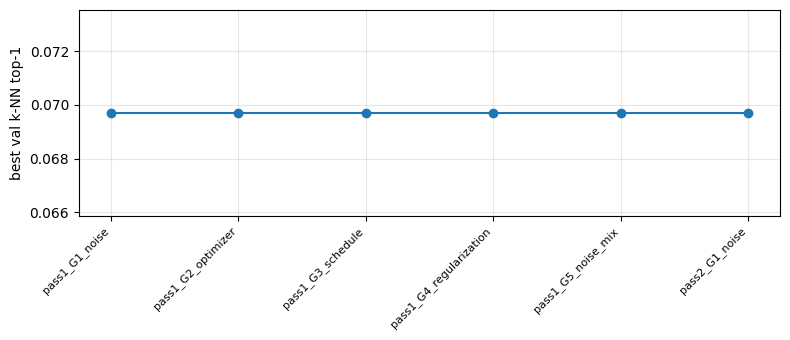

stable: True
best settings: {
 "noise_type": "salt_pepper",
 "noise_level": 0.5,
 "latent_dim": 256,
 "activation": "gelu",
 "optimizer": "adamw",
 "learning_rate": 0.001,
 "weight_decay": 0.01,
 "beta2": 0.999,
 "scheduler": "none",
 "epochs": 8,
 "batch_size": 512,
 "gauss_extra": 0.0
}
val k-NN top-1: 0.0697


In [17]:
state = load_state()
history = pd.DataFrame(state["history"])
display(history[["key", "winner", "score", "base_score", "changed"]].style.format({"score": "{:.4f}", "base_score": "{:.4f}"}))

best_after = [h["score"] if h["changed"] else h["base_score"] for h in state["history"]]
plt.figure(figsize=(8, 3.5))
plt.plot(range(1, len(best_after) + 1), best_after, marker="o")
plt.xticks(range(1, len(best_after) + 1), history.key, rotation=45, ha="right", fontsize=8)
plt.ylabel("best val k-NN top-1")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("stable:", is_stable())
print("best settings:", json.dumps(state["best"], indent=1))
print("val k-NN top-1:", round(state["best_score"], 4))

<div dir="ltr" align="left" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>Seeds: is the best really better than the runners-up? (6 runs)</p>
<ul>
<li>The 3 best different settings of all of search 2, each again with seeds 1 and 2. With seed 42 that is 3 runs per setting.</li>
<li>The table shows the mean and the std over the 3 seeds. If the best is ahead by less than about one std, the runners-up are as good a choice; then the simpler one (for example relu + adam, which train.py has) is the better one to train.</li>
</ul>
<hr>
</div>

<div dir="rtl" align="right" style="font-family: Calibri, sans-serif; font-size: 12pt; line-height: 1.5;">
<p>‏Seeds: האם הטוב באמת טוב מהבאים אחריו? (‏6 ריצות)</p>
<ul>
<li>‏3 ההגדרות השונות הכי טובות בכל חיפוש 2, כל אחת שוב עם seeds 1 ו-2. יחד עם seed 42 זה 3 ריצות לכל הגדרה.</li>
<li>הטבלה מראה את הממוצע ואת סטיית התקן על 3 ה-seeds. אם הטוב מוביל בפחות מבערך סטיית תקן אחת, הבאים אחריו בחירה טובה באותה מידה; אז עדיף לאמן את הפשוטה מהן (למשל relu + adam, שיש ב-train.py).</li>
</ul>
</div>

In [18]:
runs_dir = os.path.join(LOG_DIR, "runs")
results = []
for name in os.listdir(runs_dir):
    done_file = os.path.join(runs_dir, name, "done.json")
    if os.path.exists(done_file):
        with open(done_file) as f:
            result = json.load(f)
        if result["seed"] == config.TRAIN_SEED:
            results.append(result)
top3 = sorted(results, key=lambda r: -r["val_knn_top1"])[:3]

rows = []
for result in top3:
    scores = [result["val_knn_top1"]] + [train_run(result["settings"], seed)["val_knn_top1"] for seed in [1, 2]]
    rows.append({"settings": result["name"], "mean": pd.Series(scores).mean(), "std": pd.Series(scores).std(),
                 "seed 42": scores[0], "seed 1": scores[1], "seed 2": scores[2]})
display(pd.DataFrame(rows).style.format({c: "{:.4f}" for c in ["mean", "std", "seed 42", "seed 1", "seed 2"]}))

INFO:lightning_fabric.utilities.seed:Seed set to 1
/usr/local/lib/python3.13/dist-packages/pytorch_lightning/trainer/connectors/checkpoint_connector.py:190: .fit(ckpt_path="last") is set, but there is no last checkpoint available. No checkpoint will be loaded. HINT: Set `ModelCheckpoint(..., save_last=True)`.
/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/model_summary/model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


┏━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type       ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ encoder │ Sequential │  4.2 M │ train │     0 │
│ 1 │ decoder │ Sequential │  4.2 M │ train │     0 │
│ 2 │ loss_fn │ MSELoss    │      0 │ train │     0 │
└───┴─────────┴────────────┴────────┴───────┴───────┘

Trainable params: 8.4 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 8.4 M                                                                                                
Total estimated model params size (MB): 33.776                                                                     
Modules in train mode: 15                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Training: |          | 0/? [00:00<?, ?it/s]

... (86 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

  trained      salt_pepper0.5_l256_gelu_adamw_lr0.001_wd0.01_b20.999_none_e8_bs512_g0.25_s2: 0.0677 (best epoch 7) in 3.3 min


,settings,mean,std,seed 42,seed 1,seed 2
0,salt_pepper0.5_l256_gelu_adamw_lr0.001_wd0.01_b20.999_cosine_e8_bs256_g0,0.0678,0.0031,0.0710,0.0648,0.0677
1,salt_pepper0.5_l256_gelu_adamw_lr0.001_wd0.01_b20.999_cosine_e8_bs512_g0,0.0682,0.0022,0.0707,0.0670,0.0669
2,salt_pepper0.5_l256_gelu_adamw_lr0.001_wd0.01_b20.999_none_e8_bs512_g0.25,0.0681,0.0020,0.0702,0.0663,0.0677
